In [1]:
print("/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/neurite/tf/modelio.py")


/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/neurite/tf/modelio.py


In [2]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil
import matplotlib.pyplot as plt

import utils.functions as fc
import utils.visualization as vis
import utils.util_deep_learning as udl
import utils.util as util

import voxelmorph as vxm


# print("/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/neurite/tf/modelio.py")
# attrs, varargs, varkw, defaults = inspect.getfullargspec(func)
# attrs = inspect.getfullargspec(func)

2024-04-04 15:56:18.021394: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-04 15:56:18.021476: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-04 15:56:18.023459: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-04 15:56:18.035922: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-04 15:56:19.198327: W tensorflow/comp

## Visualize data

In [3]:
    
# %matplotlib widget

# data_train = DataLoader(batch_size=3, image_size=(193,229,193), shuffle=False, channels_first=False, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1, server=True)
# # fc.imgshow_3D("", data_train[0][0][0,0])
# fc.imgshow_3D("", data_train[0][0][0,...,0])

### Validation visualization

In [4]:
def show_generated_image(id, vxm_model, img_size, current_plane=116):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    imgs_input = np.concatenate([np.expand_dims(img_hunt3, axis=-1), np.expand_dims(img_hunt4, axis=-1)], axis=-1)
    img_gen_h4 = vxm_model(np.expand_dims(imgs_input, axis=0), training=False)
    img_gen_h4 = img_gen_h4[0][0, ...,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)
    return vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane)



# Model training

## Model creation

In [5]:
def create_vxm_model(img_shape):
    # configure unet input shape (concatenation of moving and fixed images)
    ndim = len(img_shape)
    unet_input_features = 2
    inshape = (*img_shape, unet_input_features)

    # configure unet features 
    nb_features = [
        [32, 64, 128, 256],         # encoder features
        [256, 128, 64, 32, 32, 16]  # decoder features
        # [32, 64, 128, 256, 16]
    ]
    # build model
    unet = vxm.networks.Unet(inshape=inshape, nb_features=nb_features)

    if ndim == 2:
        disp_tensor = tf.keras.layers.Conv2D(ndim, kernel_size=3, padding='same', name='disp')(unet.output)
    elif ndim == 3:
        disp_tensor = tf.keras.layers.Conv3D(ndim, kernel_size=3, padding='same', name='disp')(unet.output)
    # def_model = tf.keras.models.Model(unet.inputs, disp_tensor)
    # return def_model

    # warp the moving image with the transformer
    spatial_transformer = vxm.layers.SpatialTransformer(name='transformer')
    moving_image = tf.expand_dims(unet.input[..., 0], axis=-1)
    moved_image_tensor = spatial_transformer([moving_image, disp_tensor])

    outputs = [moved_image_tensor, disp_tensor]
    vxm_model = tf.keras.models.Model(inputs=unet.inputs, outputs=outputs)
    return vxm_model

# model = create_vmx_model((192,224))
# print(model.summary())

### Loss functions

In [6]:
mse_loss = vxm.losses.MSE().loss
dfield_loss = vxm.losses.Grad('l2').loss

def losses(h4_batch, h4_moved, dfield):
    # mse loss
    loss_mse = mse_loss(h4_batch, h4_moved)

    # gradient loss
    loss_dfield = tf.reduce_mean(dfield_loss(None, dfield))
    loss = loss_mse + 0.05 * loss_dfield
    return loss, loss_mse, loss_dfield


In [7]:
@tf.function
def train_step(vxm_model, h3_batch, h4_batch, optimizer):
    with tf.GradientTape() as model_tape:
        h4_moved, dfield = vxm_model(tf.concat([h3_batch, h4_batch], axis=-1), training=True)
        loss, loss_mse, loss_dfield = losses(h4_batch, h4_moved, dfield)

    gradients = model_tape.gradient(loss, vxm_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients, vxm_model.trainable_variables))

    return loss, loss_mse, loss_dfield

### Training

2024-04-04 15:56:49.944312: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:3b:00.0, compute capability: 7.0



Epoch 1/50


2024-04-04 15:56:53.399342: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-04-04 15:56:54.749677: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-04 15:57:03.996048: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


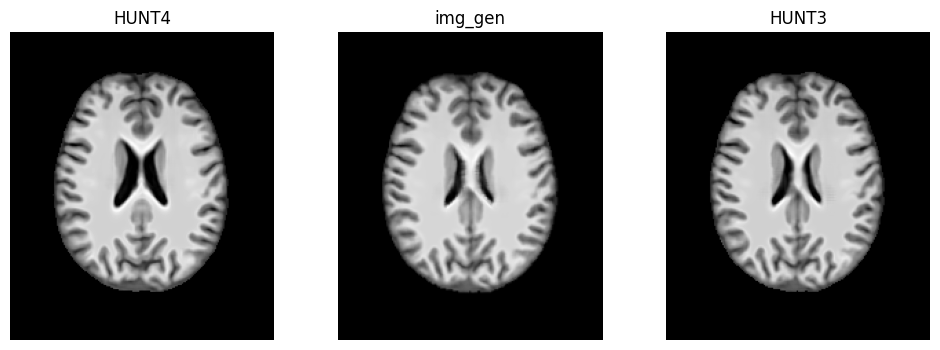

Initializing...:   0%|          | 0/300 [00:00<?, ?it/s]2024-04-04 15:57:33.263612: I external/local_xla/xla/service/service.cc:168] XLA service 0x7f932bcac4c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2024-04-04 15:57:33.263649: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-PCIE-16GB, Compute Capability 7.0
2024-04-04 15:57:33.779911: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1712239054.282485 1869847 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
loss: 0.00128	loss_mse: 0.00122	loss_dfield: 0.00113: 100%|██████████| 300/300 [15:09<00:00,  3.03s/it]



Epoch 2/50


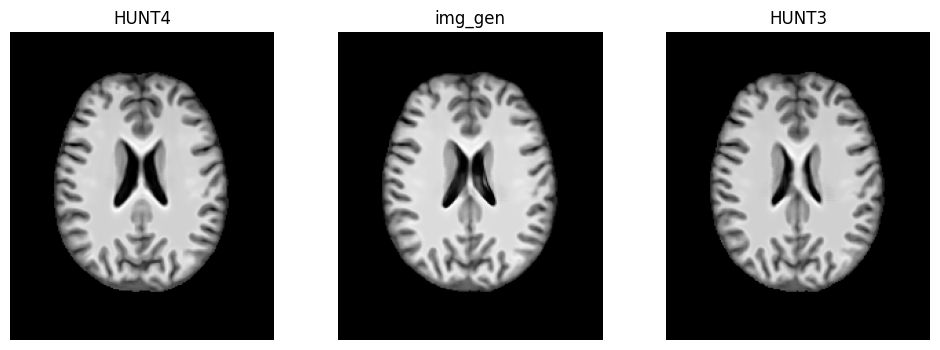

loss: 0.00067	loss_mse: 0.00058	loss_dfield: 0.00176: 100%|██████████| 300/300 [12:30<00:00,  2.50s/it]



Epoch 3/50


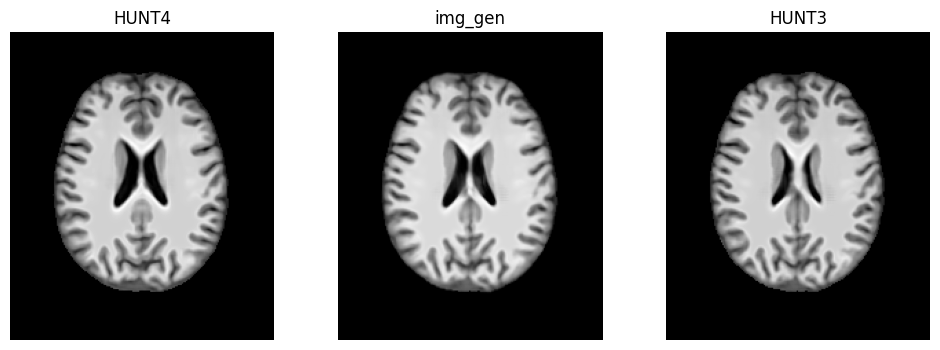

loss: 84091.62839	loss_mse: 0.02589	loss_dfield: 1681831.96928: 100%|██████████| 300/300 [12:21<00:00,  2.47s/it] 



Epoch 4/50


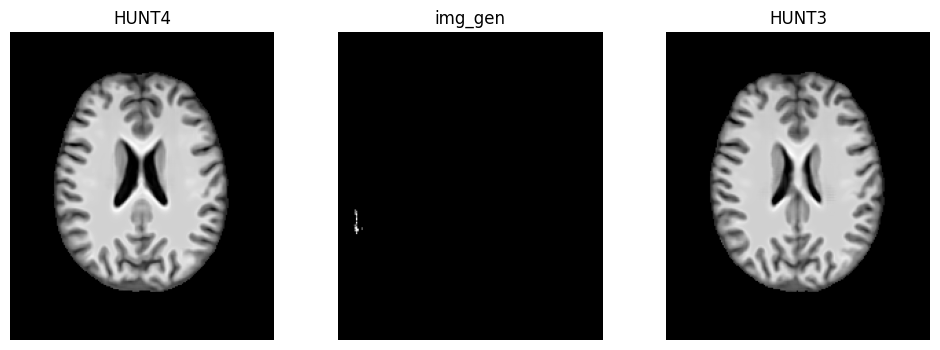

loss: 264161033.13334	loss_mse: 0.04351	loss_dfield: 5283220596.83329: 100%|██████████| 300/300 [13:41<00:00,  2.74s/it] 



Epoch 5/50


invalid value encountered in divide


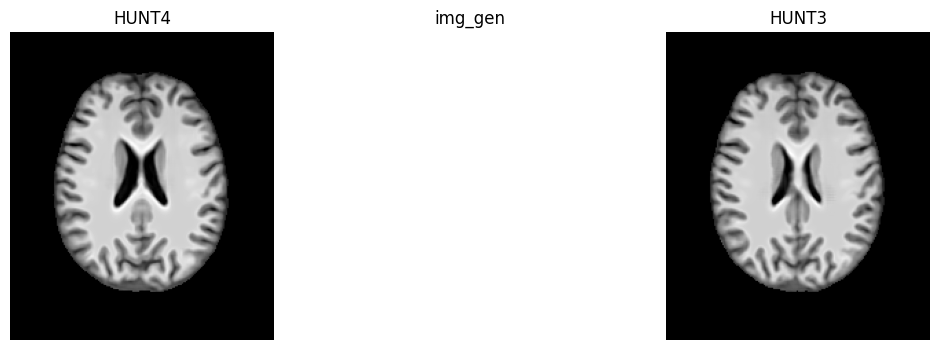

loss: 385817.21693	loss_mse: 0.04350	loss_dfield: 7716343.38000: 100%|██████████| 300/300 [14:01<00:00,  2.80s/it]



Epoch 6/50


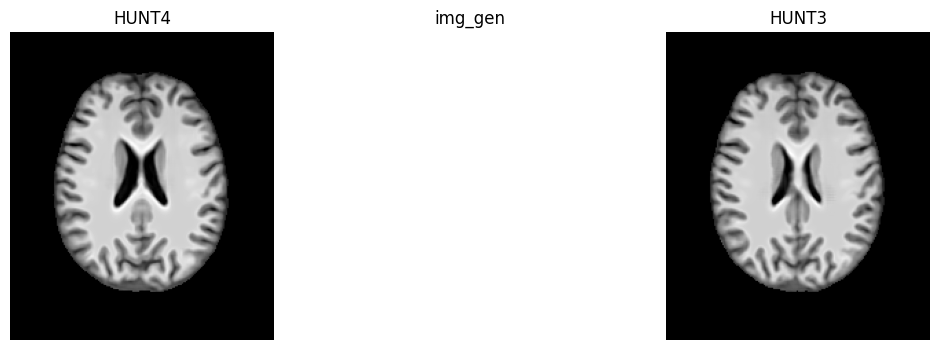

loss: 253195.09784	loss_mse: 0.04238	loss_dfield: 5063901.00000:  14%|█▍        | 42/300 [02:09<17:39,  4.11s/it]

In [8]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)
    # input_shape = (64,64,64)
    current_plane = 116

    # ---- Models
    vxm_model = create_vxm_model(input_shape)

    # optimizers
    inital_lr = 1e-3
    optimizer = tf.keras.optimizers.Adam(inital_lr)

    # ---- Data
    server = True
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=False,
                                    shuffle=True, 
                                    nb_patients=300, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 3
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    log_dir=f"{current_path}/models/logs/train"
    summary_writer = tf.summary.create_file_writer(log_dir)

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(generator_optimizer=optimizer,
                                    vxm_model=vxm_model)
    # restore checkpoint
    # checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        val_results = show_generated_image("08202", vxm_model, input_shape, current_plane=current_plane)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
            loss, loss_mse, loss_dfield = train_step(vxm_model, h3_batch, h4_batch, optimizer)
            acum_loss_train.update((loss, loss_mse, loss_dfield))
            losses_text = acum_loss_train.get_progress_bar_text(['loss', 'loss_mse', 'loss_dfield'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        # ---- Check points
        if  epoch > 0 and epoch % 2 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
        
        # ---- Learning rate
        # if epoch > 44 and epoch % 22 == 0:
        if epoch > 10 and epoch % 4 == 0:
            inital_lr *= 0.5
            optimizer.learning_rate = inital_lr

        # ---- tensorboard
        loss_mean = acum_loss_train.get_mean()
        with summary_writer.as_default():
            tf.summary.scalar('loss', loss_mean[0], step=epoch)
            tf.summary.scalar('loss_mse', loss_mean[0], step=epoch)
            tf.summary.scalar('loss_dfield', loss_mean[0], step=epoch)

            # images
            gen_image = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
            hunt4_vs_gen = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
            tf.summary.image("generated", gen_image, step=epoch)
            tf.summary.image("R: Gen - G: HUNT4", hunt4_vs_gen, step=epoch)
    

train(num_epochs=50, batch_size=1)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]


